In [1]:
import warnings
import pandas as pd
import plotly.express as px
from data import *

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

ts_user = 'MRy'
gitlab_user = 'mateusz.ryl'

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/oda/notebooks/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-5154b0e1-0452-4d9a-9215-ff1832afeacd;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# MRy

In [2]:
user_issues(ts_user).toPandas()

25/05/29 12:43:09 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

,key,summary,status,type,priority,size,size_points,status_changed_at,issue_total_hours,user_total_hours
0,CRYP-10657,[capital.com] Podawanie kluczy przez docker se...,Delivery,Story,Medium,XS,1,2025-05-28 08:03:37.901,15.5,15.0
1,CRYP-10285,[Wallet monitor] Połączenie z Vaultem,In testing,Story,Medium,M,5,2025-05-27 06:29:09.520,110.5,110.5
2,CRYP-10713,[Binance] Brak zmiany statusu feeda po rozłącz...,In Progress,Bug,High,XS,1,2025-05-26 10:48:27.180,11.0,11.0
3,CRYP-10174,[WalletMonitor] Dodanie obsługi gate.io futures,Delivered,Story,Medium,S,2,2025-05-26 09:37:47.152,81.0,34.0
4,CRYP-10660,[platform-admin] Przydzielanie kluczy nie dzia...,Delivered,Bug,Medium,None,None,2025-05-26 09:30:15.854,1.5,1.5
5,CRYP-10695,[Bitvavo] Zmiany w API,In Progress,Story,Medium,S,2,2025-05-22 06:40:19.446,14.0,14.0
6,CRYP-10571,[Mexc] Unhandled exception podczas zamykania WS,Delivery,Bug,Medium,S,2,2025-05-21 11:00:57.585,33.5,33.5
7,CRYP-10614,[Binance] Niepotrzebne logi dla statystyk feed...,Delivered,Bug,Medium,XS,1,2025-05-20 07:35:27.321,11.5,11.5
8,CRYP-10659,[MEXC] Źle nadawany timestamp raportów,In Review,Bug,High,XS,1,2025-05-14 12:33:18.054,12.0,12.0
9,CRYP-9477,[CCXT] Dodanie znacznika początku i konca nagr...,In Review,Story,Medium,S,2,2025-05-09 11:22:00.018,99.0,99.0


In [3]:
user_issues_hours_monthly(ts_user).toPandas()

,month,jira_id,summary,status,hours
0,2025-05-01,CRYP-10174,[WalletMonitor] Dodanie obsługi gate.io futures,Delivered,3.0
1,2025-05-01,CRYP-10285,[Wallet monitor] Połączenie z Vaultem,In testing,21.5
2,2025-05-01,CRYP-10571,[Mexc] Unhandled exception podczas zamykania WS,Delivery,9.5
3,2025-05-01,CRYP-10614,[Binance] Niepotrzebne logi dla statystyk feed...,Delivered,1.5
4,2025-05-01,CRYP-10657,[capital.com] Podawanie kluczy przez docker se...,Delivery,15.0
5,2025-05-01,CRYP-10659,[MEXC] Źle nadawany timestamp raportów,In Review,12.0
6,2025-05-01,CRYP-10660,[platform-admin] Przydzielanie kluczy nie dzia...,Delivered,1.5
7,2025-05-01,CRYP-10695,[Bitvavo] Zmiany w API,In Progress,14.0
8,2025-05-01,CRYP-10713,[Binance] Brak zmiany statusu feeda po rozłącz...,In Progress,11.0
9,2025-05-01,CRYP-9477,[CCXT] Dodanie znacznika początku i konca nagr...,In Review,13.5


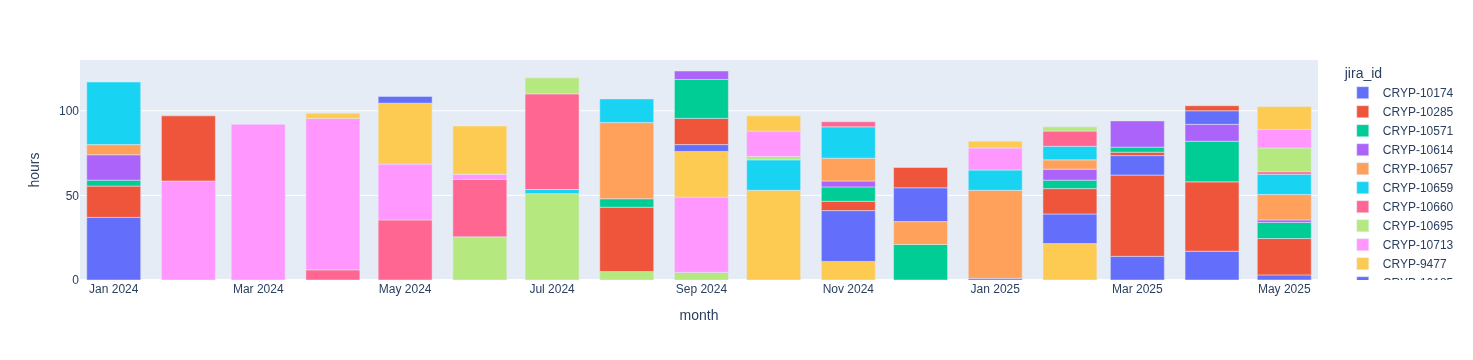

In [4]:
px.bar(user_issues_hours_monthly(ts_user).toPandas(),x='month',y='hours',color='jira_id',hover_data={'summary':True})

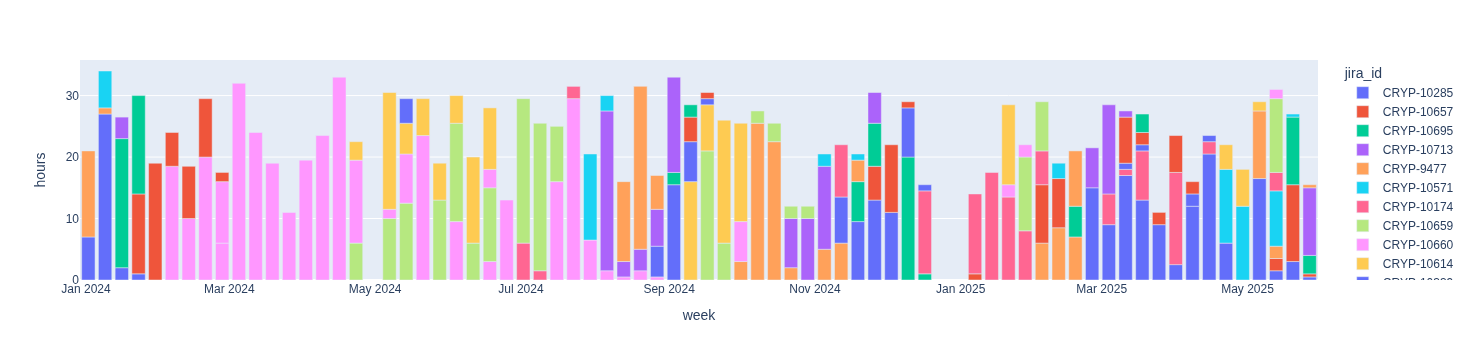

In [5]:
px.bar(user_issues_hours_weekly(ts_user).toPandas(),x='week',y='hours',color='jira_id',hover_data={'summary':True})

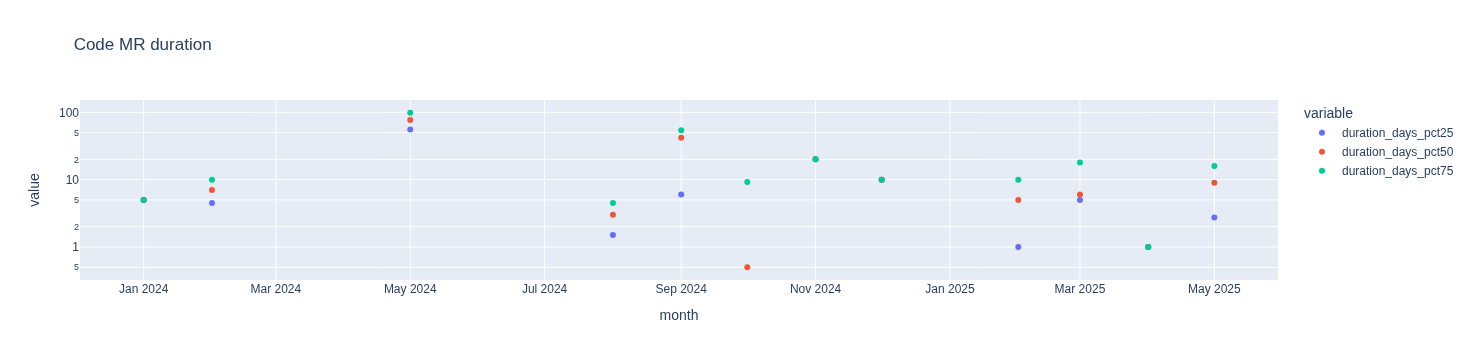

In [6]:
px.scatter(user_mrs_duration(gitlab_user).toPandas(),x='month',y=['duration_days_pct25','duration_days_pct50','duration_days_pct75'], log_y=True,title='Code MR duration')

In [7]:
px.bar(user_code_commits(gitlab_user).toPandas(),x='month',y=['additions','deletions'],log_y=True,title='Commits',barmode='group')

In [8]:
users_hours.where(f.col('user')==ts_user).toPandas()

,month,user,jira_hours,other_hours,total_hours,other_hours_pct
0,2025-05-01,MRy,102.5,40.5,143.0,28.321678
1,2025-04-01,MRy,103.0,41.0,144.0,28.472222
2,2025-03-01,MRy,94.0,34.0,128.0,26.562500
3,2025-02-01,MRy,90.5,53.5,144.0,37.152778
4,2025-01-01,MRy,82.0,46.0,128.0,35.937500
5,2024-12-01,MRy,66.5,29.5,96.0,30.729167
6,2024-11-01,MRy,93.5,42.5,136.0,31.250000
7,2024-10-01,MRy,97.0,79.0,176.0,44.886364
8,2024-09-01,MRy,123.5,44.5,168.0,26.488095
9,2024-08-01,MRy,107.0,53.0,160.0,33.125000


In [9]:
user_other_hours(ts_user).toPandas()

,month,task_desc,other_hours
0,2025-05-01,Wsparcie liquee,1.0
1,2025-05-01,Spotkania scrumowe,24.0
2,2025-05-01,Code review,9.5
3,2025-05-01,Spotkania wewnątrzfirmowe,4.0
4,2025-05-01,Konsultacje,2.0
5,2025-04-01,Spotkania scrumowe,21.0
6,2025-04-01,Spotkania wewnątrzfirmowe,3.0
7,2025-04-01,Wsparcie liquee,2.0
8,2025-04-01,Code review,15.0
9,2025-03-01,Spotkania scrumowe,18.5
